# Hospital Patient Flow Analysis
## Malawi District-Hospital Operations Case Study

**Author:** Chico Mkandawire

**Purpose:** Demonstrate an end-to-end healthcare operations analytics workflow using Python, data-quality controls, queue simulation, descriptive statistics, hypothesis testing, and visualisation. The analysis focuses on patient waiting times, department congestion, shared-service bottlenecks, and operational patterns.

**Data note:** Encounter records are generated reproducibly for this case study. Results describe the modelled dataset and are not measurements of an operating health facility.

---

## 1. Simulate Hospital Patient Flow

### 1.1 Hospital structure

Six clinical departments, each with its own registration/triage/consultation staffing, plus two **shared hospital-wide resources** (Laboratory, Pharmacy) that patients from every department draw on. Shared-service waiting is explored for laboratory-requested encounters in Sections 7.4 and 11.4; pharmacy is part of the simulation but is not separately tested in this notebook.

Service times are drawn from **triangular distributions** (a minimum, a most-likely value, and a maximum) rather than uniform ones — most consultations, registrations, etc. are quick, but a realistic minority run long, and that right-skew is what allows backlogs to form rather than a queue that always drains smoothly.


In [ ]:
import sys
import subprocess
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Resolve the repository in local Jupyter and Google Colab.
cwd = Path.cwd().resolve()
if (cwd / "src" / "patient_flow").is_dir() and (cwd / "config" / "default.yaml").is_file():
    PROJECT_ROOT = cwd
elif cwd.name.lower() == "notebooks" and (cwd.parent / "src" / "patient_flow").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd / "Hospital-Patient-Flow-Analysis"
    if not (PROJECT_ROOT / "src" / "patient_flow").is_dir():
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/MkandawireChico/Hospital-Patient-Flow-Analysis.git",
             str(PROJECT_ROOT)],
            check=True,
        )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from patient_flow.simulation import generate_case_study_data

CHART_DIR = PROJECT_ROOT / "visuals" / "charts"
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
for output_dir in (CHART_DIR, RAW_DATA_DIR, PROCESSED_DATA_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

print(f"Project workspace: {PROJECT_ROOT}")
print(f"Charts will be saved to: {CHART_DIR}")
print("Simulation settings are loaded from config/default.yaml.")

### 1.2 Helper functions

Arrival times follow an hour-of-day distribution with a defined peak window (morning peak for daytime departments, evening peak for Emergency, which also runs overnight). `process_queue` is the core queueing engine: given a sorted list of "ready times" (when each patient becomes eligible for a stage) and a fixed number of servers, it assigns each patient to the earliest-available server — exactly how a real limited-staff queue behaves.


In [ ]:
print("Queue simulation and data-generation helpers are provided by src/patient_flow/simulation.py.")
print("The module uses the repository's YAML configuration as its single source of truth.")

### 1.3 Run the simulation — 365 days, all departments

For each simulated day, arrivals are generated by department and processed through registration, triage, and consultation queues. Patients requesting Laboratory or Pharmacy are then pooled into shared hospital-wide queues.

**Simulation boundary:** Server availability is reinitialised at the start of each calendar day. The model therefore captures competition for capacity within a day, but does not carry an unfinished queue across midnight. Interpret late-night and overnight results with this limitation in mind.

In [ ]:
df, raw = generate_case_study_data(PROJECT_ROOT / "config" / "default.yaml")
print(f"Clean simulated encounters: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Raw encounters after configured quality-issue injection: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
df.head()

### 1.4 Derived timing fields (computed from the simulation, not asserted)


In [ ]:
print("Derived timing, length-of-stay, and satisfaction fields are generated by the simulation module.")
df[[
    "Total_Waiting_Time",
    "Consultation_Duration",
    "Total_Length_of_Stay",
    "Patient_Satisfaction_Score",
]].describe().round(2)

### 1.5 Quick sanity check of the clean simulation

Before injecting any data-quality problems, confirm the relationships the project brief asked for actually emerged from the simulation mechanics rather than being hard-coded.


In [54]:
print(f"Correlation: Queue_Size vs Total_Waiting_Time: {df['Queue_Size'].corr(df['Total_Waiting_Time']):.3f}")
print(f"Correlation: Total_Waiting_Time vs Patient_Satisfaction_Score: {df['Total_Waiting_Time'].corr(df['Patient_Satisfaction_Score']):.3f}")
print()
print("Mean Total_Waiting_Time by Priority_Level:")
print(df.groupby("Priority_Level")["Total_Waiting_Time"].mean().round(2))
print()
print("Mean Total_Length_of_Stay by Disposition:")
print(df.groupby("Disposition")["Total_Length_of_Stay"].mean().round(2))
print()
print(f"Share of encounters waiting >60 minutes: {(df['Total_Waiting_Time'] > 60).mean():.1%}")




Correlation: Queue_Size vs Total_Waiting_Time: 0.924
Correlation: Total_Waiting_Time vs Patient_Satisfaction_Score: -0.810

Mean Total_Waiting_Time by Priority_Level:
Priority_Level
Emergency    3.81
Routine     15.92
Urgent      11.98
Name: Total_Waiting_Time, dtype: float64

Mean Total_Length_of_Stay by Disposition:
Disposition
Admitted       177.54
Discharged     103.00
Referred Out   100.60
Name: Total_Length_of_Stay, dtype: float64

Share of encounters waiting >60 minutes: 7.1%


**Interpretation guardrail:** The satisfaction score is generated using a formula that subtracts a component based on waiting time (and admission status), then adds random noise. Its negative correlation with waiting time is therefore partly built into the data-generating process; it is not an independent patient-experience finding.

**Important modelling clarification:** the consultation queue is first-come, first-served (FCFS). Priority is assigned for analysis and influences the probability of requesting a laboratory test and being admitted, but it does **not** change queue order or waiting time in this version of the simulation. Therefore, differences in mean waits by priority are descriptive and may reflect the mix of departments and service capacity; they must not be presented as evidence that emergency triage priority reduced waiting time. Admitted patients have an additional modelled stay component, and queue size is expected to be associated with waiting time because it is calculated from the same queue process. Patient satisfaction is also generated partly from waiting time, so its negative association with waiting is built into the score formula rather than independently discovered.

## 2. Inject Realistic Data-Quality Problems

The simulation above is a "perfect world" record. Real hospital records systems have problems. Seven categories are deliberately injected, each with its own random seed for reproducibility:

1. **Missing values** — random `NaN`s in non-critical fields (`Patient_Satisfaction_Score`, `Referral_Status`) — ~2.5% each.
2. **Duplicate patient encounter records** — ~1% of rows exactly duplicated (the same visit logged twice).
3. **Impossible timestamps** — ~0.5% of rows get `Consultation_Start_Time` set *before* `Arrival_Time` (a data-entry/clock error).
4. **Negative waiting times** — ~0.5% of rows get `Total_Waiting_Time` forced negative directly (a calculation/entry error further downstream in a real system).
5. **Extreme outliers** — ~0.5% of rows get `Total_Length_of_Stay` multiplied 5–8x (a genuine unusual case or a data error — indistinguishable without chart review, which is realistic).
6. **Incorrect department values** — ~0.3% of rows get `Department` overwritten with a typo'd/invalid value (e.g. `"OPD "` with trailing space, `"emergency"` lowercase, `"Unknown"`).
7. **Missing laboratory timestamps where no lab was requested** — this one is **not injected as an error**: it is the *correct, expected* state of the clean data (a patient with no lab request should have no lab timestamps), and Section 3 checks that this is true rather than assuming it.


In [ ]:
# Quality issues have already been injected by the configuration-driven generator.
# This cell reports the resulting counts without applying a second injection pass.
baseline_los = df.set_index("Patient_ID")["Total_Length_of_Stay"]
baseline_los_for_raw = raw["Patient_ID"].map(baseline_los)
impossible_timestamp = pd.to_datetime(raw["Consultation_Start_Time"]) < pd.to_datetime(raw["Arrival_Time"])
invalid_departments = ~raw["Department"].isin([
    "Outpatient Department", "Emergency", "Maternal Health",
    "Paediatrics", "Chronic Care", "TB/HIV Clinic",
])
print(f"Missing Patient_Satisfaction_Score: {raw['Patient_Satisfaction_Score'].isna().sum():,}")
print(f"Missing Referral_Status:             {raw['Referral_Status'].isna().sum():,}")
print(f"Duplicate rows added:                {len(raw) - len(df):,}")
print(f"Impossible timestamps:               {impossible_timestamp.sum():,}")
print(f"Negative waiting times:              {(pd.to_numeric(raw['Total_Waiting_Time'], errors='coerce') < 0).sum():,}")
print(f"Extreme LOS outliers:                 {(raw['Total_Length_of_Stay'] > baseline_los_for_raw * 4.9).sum():,}")
print(f"Incorrect department values:         {invalid_departments.sum():,}")
print(f"Final raw shape: {raw.shape}")

In [56]:
RAW_DIR = RAW_DATA_DIR
raw.to_csv(RAW_DIR / "hospital_patient_flow_synthetic.csv", index=False)
print(f"Raw synthetic dataset saved: {raw.shape[0]:,} rows -> {RAW_DIR / 'hospital_patient_flow_synthetic.csv'}")


Raw synthetic dataset saved: 35,418 rows -> /content/data/raw/hospital_patient_flow_synthetic.csv


## 3. Data Inspection

Treat `raw` exactly as if it just arrived from the hospital's records system.


In [57]:
print("Shape:", raw.shape)
raw.info()


Shape: (35418, 40)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35418 entries, 0 to 35417
Data columns (total 40 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Patient_ID                  35418 non-null  object        
 1   Visit_Date                  35418 non-null  object        
 2   Day_of_Week                 35418 non-null  object        
 3   Department                  35418 non-null  object        
 4   Arrival_Time                35418 non-null  datetime64[ns]
 5   Registration_Time           35418 non-null  datetime64[ns]
 6   Registration_End_Time       35418 non-null  datetime64[ns]
 7   Triage_Start_Time           35418 non-null  datetime64[ns]
 8   Triage_End_Time             35418 non-null  datetime64[ns]
 9   Consultation_Start_Time     35418 non-null  datetime64[ns]
 10  Consultation_End_Time       35418 non-null  datetime64[ns]
 11  Priority_Level              35418 n

In [58]:
missing = raw.isnull().sum()
missing[missing > 0].sort_values(ascending=False)


,0
Laboratory_Start_Time,19774
Laboratory_End_Time,19774
Laboratory_Wait_Time,19774
Laboratory_Duration,19774
Pharmacy_End_Time,11738
Pharmacy_Start_Time,11738
_pharm_ready,11738
Pharmacy_Duration,11738
Pharmacy_Wait_Time,11738
Referral_Status,888


In [59]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("Negative Total_Waiting_Time:", (raw['Total_Waiting_Time'] < 0).sum())
print("Consultation before Arrival (impossible):", (raw['Consultation_Start_Time'] < raw['Arrival_Time']).sum())
print()
print("Distinct Department values (should be exactly 6):")
print(raw['Department'].value_counts())


Exact duplicate rows: 336
Negative Total_Waiting_Time: 177
Consultation before Arrival (impossible): 177

Distinct Department values (should be exactly 6):
Department
Outpatient Department    14243
Paediatrics               6894
Emergency                 5808
Maternal Health           3433
Chronic Care              2652
TB/HIV Clinic             2282
emergency                   34
Unknown                     23
Outpatient department       22
PAEDS                       15
OPD                         12
Name: count, dtype: int64


In [60]:
# Confirm: rows with NO lab request should have NO lab timestamps (this should already be true)
no_lab_but_has_timestamp = raw[(~raw["Laboratory_Requested"]) & (raw["Laboratory_Start_Time"].notna())]
print(f"Rows with no lab request but a lab timestamp present: {len(no_lab_but_has_timestamp)}")
print("(Expected: 0 — the simulation never assigns lab timestamps unless Laboratory_Requested is True)")


Rows with no lab request but a lab timestamp present: 0
(Expected: 0 — the simulation never assigns lab timestamps unless Laboratory_Requested is True)


## 4. Data Cleaning

The notebook applies focused checks for the deliberately injected data-quality cases. Missing laboratory timestamps for patients who did not request a test are expected, not an error.

1. **Drop exact duplicate rows.**
2. **Fix known department aliases** (`"OPD "`, `"Outpatient department"`, `"emergency"`, `"PAEDS"`); flag `"Unknown"` rather than guessing its department.
3. **Flag the injected impossible timestamp** (`Consultation_Start_Time < Arrival_Time`) rather than silently deleting the encounter. Keep it for volume counts, but exclude its invalid wait from wait-time analysis.
4. **Flag injected negative total waits** and exclude them from waiting-time analysis.
5. **Investigate extreme length-of-stay values** with an IQR rule; flag rather than delete because an unusually long stay may be genuine.
6. **Leave missing satisfaction and referral values missing** rather than fabricating them through imputation.

**Alignment with the repository pipeline:** this notebook's teaching workflow focuses on the injected anomalies above. The production cleaning module in `src/patient_flow/cleaning.py` applies broader checks across available stage timestamps and measured stage-wait columns. The dashboard's processed dataset should be generated through the repository pipeline.


In [61]:
before = len(raw)
raw = raw.drop_duplicates()
print(f"Dropped {before - len(raw):,} exact duplicate rows -> {len(raw):,} remaining")

dept_fix_map = {
    "OPD ": "Outpatient Department",
    "Outpatient department": "Outpatient Department",
    "emergency": "Emergency",
    "PAEDS": "Paediatrics",
}
raw["Department"] = raw["Department"].replace(dept_fix_map)
raw["Department_Data_Error"] = raw["Department"] == "Unknown"
print(f"Standardized department name variants; {raw['Department_Data_Error'].sum()} rows still flagged 'Unknown' (cannot be safely inferred)")
print()
print(raw["Department"].value_counts())


Dropped 336 exact duplicate rows -> 35,082 remaining
Standardized department name variants; 23 rows still flagged 'Unknown' (cannot be safely inferred)

Department
Outpatient Department    14140
Paediatrics               6859
Emergency                 5781
Maternal Health           3391
Chronic Care              2621
TB/HIV Clinic             2267
Unknown                     23
Name: count, dtype: int64


In [62]:
raw["Impossible_Timestamp_Flag"] = raw["Consultation_Start_Time"] < raw["Arrival_Time"]
raw["Negative_Wait_Flag"] = raw["Total_Waiting_Time"] < 0

print(f"Rows flagged with impossible timestamps: {raw['Impossible_Timestamp_Flag'].sum()}")
print(f"Rows flagged with negative waiting time:  {raw['Negative_Wait_Flag'].sum()}")

# For duration-based analysis downstream, exclude flagged rows from Total_Waiting_Time specifically
# (kept in the dataset, just excluded from wait-time calculations via this helper column)
raw["Total_Waiting_Time_Valid"] = np.where(
    raw["Impossible_Timestamp_Flag"] | raw["Negative_Wait_Flag"], np.nan, raw["Total_Waiting_Time"]
)


Rows flagged with impossible timestamps: 177
Rows flagged with negative waiting time:  177


In [63]:
q1 = raw["Total_Length_of_Stay"].quantile(0.25)
q3 = raw["Total_Length_of_Stay"].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

raw["LOS_Outlier_Flag"] = raw["Total_Length_of_Stay"] > upper_bound
print(f"IQR upper bound for Total_Length_of_Stay: {upper_bound:.1f} minutes")
print(f"Rows flagged as LOS outliers: {raw['LOS_Outlier_Flag'].sum():,} ({raw['LOS_Outlier_Flag'].mean():.2%})")

# A separate, tighter check for the specifically injected extreme multiplier cases
extreme_los = raw[raw["Total_Length_of_Stay"] > raw["Total_Length_of_Stay"].quantile(0.999)]
print(f"Most extreme 0.1% of LOS values range: {extreme_los['Total_Length_of_Stay'].min():.0f} - {extreme_los['Total_Length_of_Stay'].max():.0f} minutes")


IQR upper bound for Total_Length_of_Stay: 300.3 minutes
Rows flagged as LOS outliers: 1,650 (4.70%)
Most extreme 0.1% of LOS values range: 1167 - 2621 minutes


**Missing values are left as missing.** No imputation is applied to `Patient_Satisfaction_Score` or `Referral_Status` — analyses using these fields simply report on the subset where they were recorded, with the sample size stated alongside any result (see Section 8).


## 5. Feature Engineering

| Field | Definition | Purpose |
|---|---|---|
| `Arrival_Hour` | hour component of `Arrival_Time` | arrival-pattern analysis |
| `Peak_Period` | `"Peak"` for arrivals from 08:00 through 09:59 for **all departments**; otherwise `"Non-Peak"` | consistent hospital-wide comparison window; this is not each department's own simulated peak |
| `Long_Wait_Flag` | `Total_Waiting_Time_Valid > 60` minutes; missing when the total wait is invalid | apply the project's explicit long-wait threshold to valid waits |
| `High_Congestion_Flag` | `Queue_Size` at or above the **hospital-wide** 75th percentile | flag relatively high queue sizes across the full encounter dataset; this is not a department-specific threshold |


In [64]:
raw["Arrival_Hour"] = raw["Arrival_Time"].dt.hour

# Use the same shared 08:00–09:59 comparison window across departments.
# This is a project-wide analytical definition, not each department's
# simulated arrival peak (Emergency is modelled with an evening peak).
raw["Peak_Period"] = np.where(
    raw["Arrival_Hour"].between(8, 9), "Peak", "Non-Peak"
)

# Missing/invalid waits remain missing in the long-wait indicator so rates use
# only encounters with a valid total waiting time.
raw["Long_Wait_Flag"] = (
    raw["Total_Waiting_Time_Valid"].gt(60)
    .where(raw["Total_Waiting_Time_Valid"].notna())
)

# Match the project pipeline's hospital-wide upper-quartile congestion rule.
queue_q75 = raw["Queue_Size"].quantile(0.75)
raw["High_Congestion_Flag"] = raw["Queue_Size"] >= queue_q75

print("Peak_Period counts:\n", raw["Peak_Period"].value_counts())
print()
print("Long_Wait_Flag counts (valid waits only):\n", raw["Long_Wait_Flag"].value_counts(dropna=False))
print()
print("High_Congestion_Flag counts:\n", raw["High_Congestion_Flag"].value_counts())

Peak_Period counts:
 Peak_Period
Non-Peak    22127
Peak        12955
Name: count, dtype: int64

Long_Wait_Flag counts (valid waits only):
 Long_Wait_Flag
False    32257
True      2471
NaN        354
Name: count, dtype: int64

High_Congestion_Flag counts:
 High_Congestion_Flag
False    23885
True     11197
Name: count, dtype: int64


## 6. Descriptive Statistics


In [65]:
raw[["Total_Waiting_Time_Valid", "Consultation_Duration", "Total_Length_of_Stay",
     "Queue_Size", "Patient_Satisfaction_Score"]].describe().round(2)


,Total_Waiting_Time_Valid,Consultation_Duration,Total_Length_of_Stay,Queue_Size,Patient_Satisfaction_Score
count,"34,728.00","35,082.00","35,082.00","35,082.00","34,205.00"
mean,13.75,19.65,111.47,2.80,4.39
std,25.00,8.57,102.12,2.94,0.90
min,0.00,6.04,14.86,1.00,1.00
25%,0.00,13.40,44.38,1.00,4.00
50%,0.00,18.07,79.84,2.00,5.00
75%,16.99,23.84,146.76,3.00,5.00
max,197.48,59.62,"2,621.43",23.00,5.00


In [66]:
print(f"Total patient encounters analysed: {len(raw):,}")
print(f"Date range: {raw['Visit_Date'].min()} to {raw['Visit_Date'].max()}")
print(f"Departments: {raw['Department'].nunique() - 1} valid (excluding 'Unknown')")
print()
print("Encounters by department:")
print(raw["Department"].value_counts())
print()
print("Encounters by priority level:")
print(raw["Priority_Level"].value_counts())
print()
print("Disposition breakdown:")
print(raw["Disposition"].value_counts(normalize=True).round(3))


Total patient encounters analysed: 35,082
Date range: 2025-01-01 to 2025-12-31
Departments: 6 valid (excluding 'Unknown')

Encounters by department:
Department
Outpatient Department    14140
Paediatrics               6859
Emergency                 5781
Maternal Health           3391
Chronic Care              2621
TB/HIV Clinic             2267
Unknown                     23
Name: count, dtype: int64

Encounters by priority level:
Priority_Level
Routine      23643
Urgent        7628
Emergency     3811
Name: count, dtype: int64

Disposition breakdown:
Disposition
Discharged     0.88
Admitted       0.08
Referred Out   0.04
Name: proportion, dtype: float64


## 7. Waiting-Time Analysis

### 7.1 Overall distribution


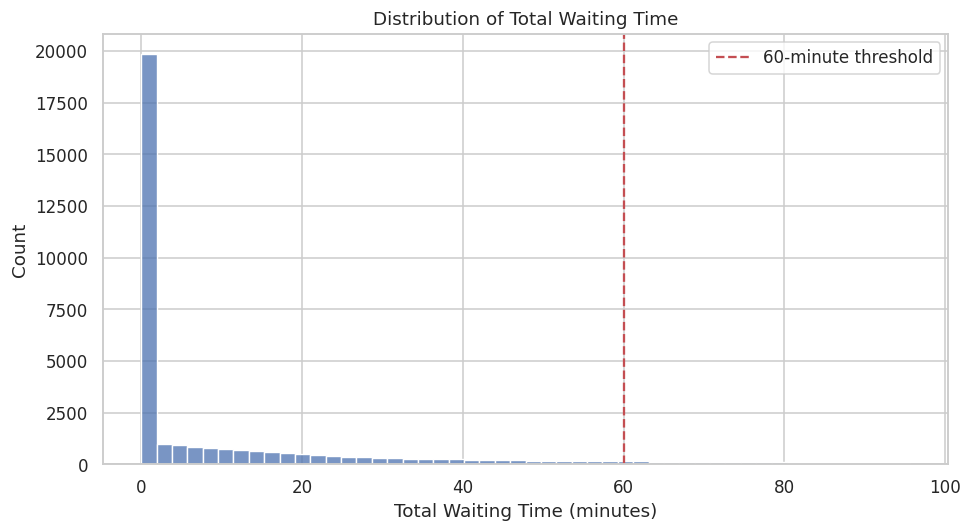

Median waiting time: 0.0 min
Mean waiting time: 13.8 min
Share waiting >60 min: 7.1%


In [67]:
fig, ax = plt.subplots(figsize=(9, 5))
valid_waits = raw["Total_Waiting_Time_Valid"].dropna()
sns.histplot(valid_waits[valid_waits <= valid_waits.quantile(0.98)], bins=50, ax=ax, color="#4C72B0")
ax.axvline(60, color="#C44E52", linestyle="--", label="60-minute threshold")
ax.set_xlabel("Total Waiting Time (minutes)")
ax.set_title("Distribution of Total Waiting Time")
ax.legend()
plt.tight_layout()
plt.savefig(CHART_DIR / "01_waiting_time_distribution.png", dpi=140, bbox_inches="tight")
plt.show()

print(f"Median waiting time: {valid_waits.median():.1f} min")
print(f"Mean waiting time: {valid_waits.mean():.1f} min")
print(f"Share waiting >60 min: {(valid_waits > 60).mean():.1%}")


### 7.2 Waiting time by department


In [68]:
dept_wait = raw.groupby("Department")["Total_Waiting_Time_Valid"].agg(["mean", "median", "count"]).round(2)
dept_wait = dept_wait[dept_wait.index != "Unknown"].sort_values("mean", ascending=False)
dept_wait


,mean,median,count
Department,,,
Outpatient Department,24.68,10.66,14002
Maternal Health,15.32,0.00,3360
Chronic Care,10.38,0.00,2594
TB/HIV Clinic,7.25,0.00,2247
Paediatrics,4.33,0.00,6788
Emergency,1.35,0.00,5714


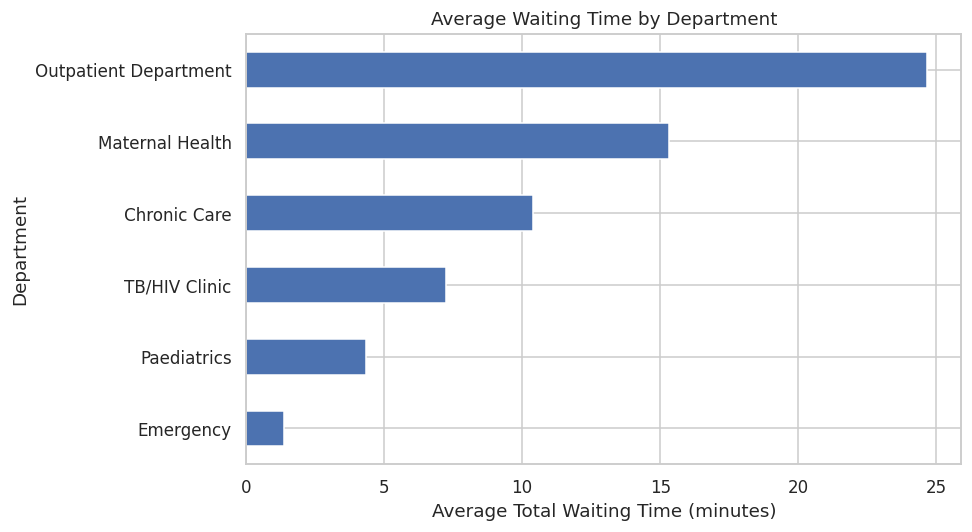

In [69]:
fig, ax = plt.subplots(figsize=(9, 5))
dept_wait["mean"].sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Average Total Waiting Time (minutes)")
ax.set_title("Average Waiting Time by Department")
plt.tight_layout()
plt.savefig(CHART_DIR / "02_avg_waiting_time_by_department.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.3 Waiting time by priority level and age group


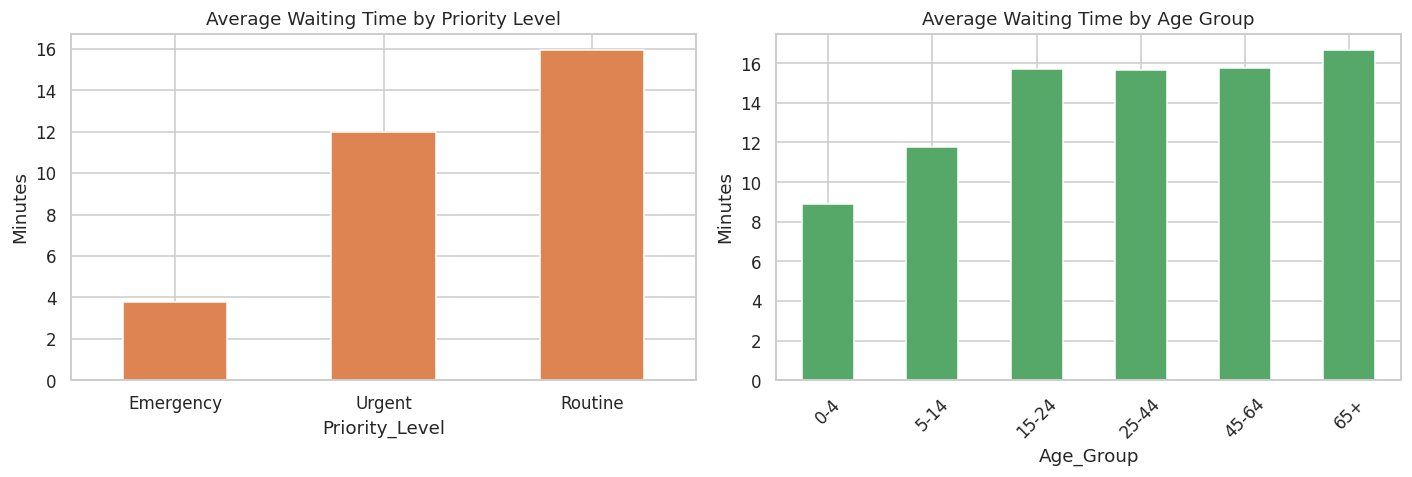

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

priority_wait = raw.groupby("Priority_Level")["Total_Waiting_Time_Valid"].mean().reindex(["Emergency","Urgent","Routine"])
priority_wait.plot(kind="bar", ax=axes[0], color="#DD8452")
axes[0].set_title("Average Waiting Time by Priority Level")
axes[0].set_ylabel("Minutes")
axes[0].tick_params(axis='x', rotation=0)

age_wait = raw.groupby("Age_Group")["Total_Waiting_Time_Valid"].mean().reindex(["0-4","5-14","15-24","25-44","45-64","65+"])
age_wait.plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set_title("Average Waiting Time by Age Group")
axes[1].set_ylabel("Minutes")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(CHART_DIR / "03_waiting_time_priority_age.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.4 Laboratory-related waiting


In [71]:
lab_patients = raw[raw["Laboratory_Requested"]]
non_lab_patients = raw[~raw["Laboratory_Requested"]]

print(f"Patients requiring laboratory tests: {len(lab_patients):,} ({len(lab_patients)/len(raw):.1%})")
print(f"Average Laboratory_Wait_Time: {lab_patients['Laboratory_Wait_Time'].mean():.1f} min")
print(f"Average Laboratory_Duration:  {lab_patients['Laboratory_Duration'].mean():.1f} min")
print()
print(f"Average Total_Length_of_Stay WITH lab request:    {lab_patients['Total_Length_of_Stay'].mean():.1f} min")
print(f"Average Total_Length_of_Stay WITHOUT lab request: {non_lab_patients['Total_Length_of_Stay'].mean():.1f} min")


Patients requiring laboratory tests: 15,498 (44.2%)
Average Laboratory_Wait_Time: 68.4 min
Average Laboratory_Duration:  45.2 min

Average Total_Length_of_Stay WITH lab request:    177.1 min
Average Total_Length_of_Stay WITHOUT lab request: 59.5 min


## 8. Department Comparison

### 8.1 Patient volume by department


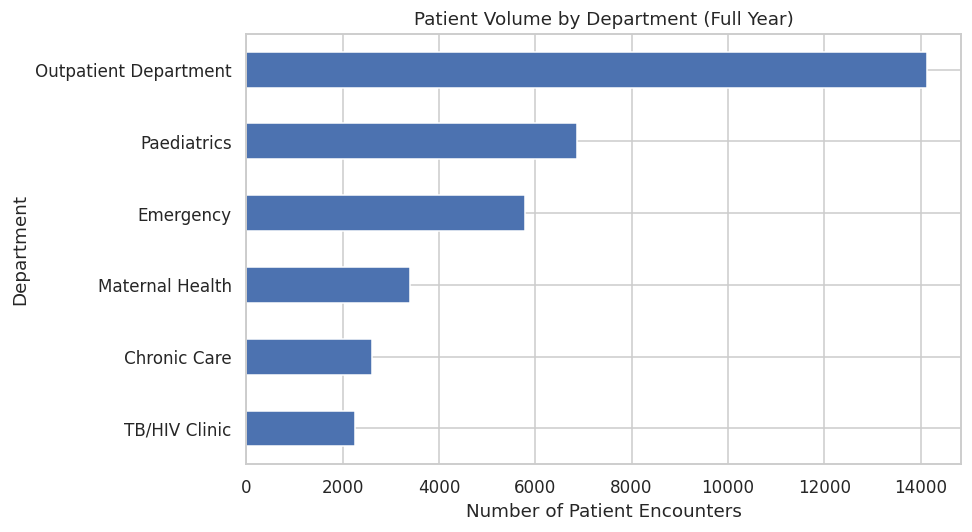

In [72]:
dept_volume = raw[raw["Department"] != "Unknown"]["Department"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
dept_volume.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Number of Patient Encounters")
ax.set_title("Patient Volume by Department (Full Year)")
plt.tight_layout()
plt.savefig(CHART_DIR / "04_patient_volume_by_department.png", dpi=140, bbox_inches="tight")
plt.show()


### 8.2 Department performance summary (waiting time, LOS, satisfaction)


In [73]:
dept_performance = raw[raw["Department"] != "Unknown"].groupby("Department").agg(
    Patients=("Patient_ID", "count"),
    Avg_Wait_Min=("Total_Waiting_Time_Valid", "mean"),
    Median_Wait_Min=("Total_Waiting_Time_Valid", "median"),
    Long_Wait_Pct=("Long_Wait_Flag", "mean"),
    Avg_LOS_Min=("Total_Length_of_Stay", "mean"),
    Avg_Satisfaction=("Patient_Satisfaction_Score", "mean"),
).round(2).sort_values("Avg_Wait_Min", ascending=False)
dept_performance

,Patients,Avg_Wait_Min,Median_Wait_Min,Long_Wait_Pct,Avg_LOS_Min,Avg_Satisfaction
Department,,,,,,
Outpatient Department,14140,24.68,10.66,0.15,107.12,4.09
Maternal Health,3391,15.32,0.00,0.07,118.77,4.35
Chronic Care,2621,10.38,0.00,0.03,127.38,4.49
TB/HIV Clinic,2267,7.25,0.00,0.01,129.63,4.60
Paediatrics,6859,4.33,0.00,0.00,92.20,4.67
Emergency,5781,1.35,0.00,0.00,126.31,4.67


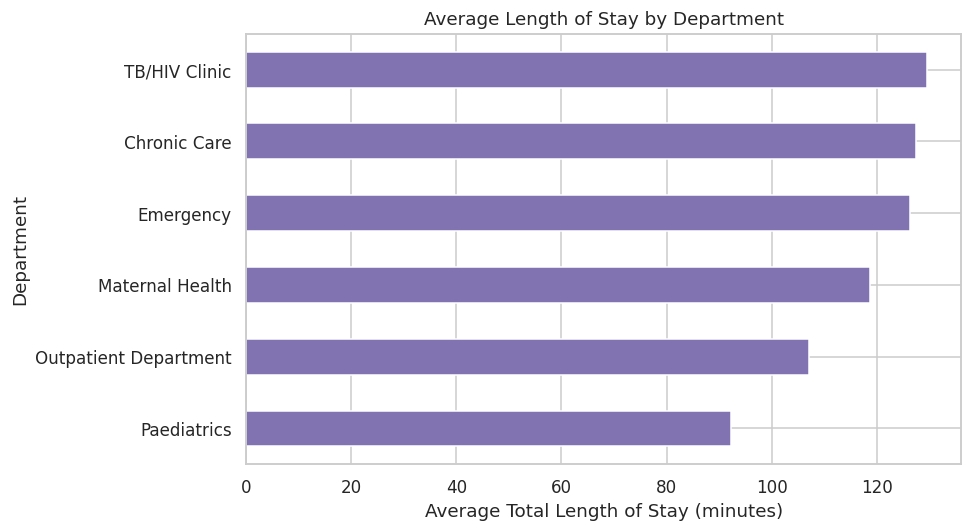

In [74]:
fig, ax = plt.subplots(figsize=(9, 5))
dept_performance["Avg_LOS_Min"].sort_values().plot(kind="barh", ax=ax, color="#8172B2")
ax.set_xlabel("Average Total Length of Stay (minutes)")
ax.set_title("Average Length of Stay by Department")
plt.tight_layout()
plt.savefig(CHART_DIR / "05_avg_los_by_department.png", dpi=140, bbox_inches="tight")
plt.show()


### 8.3 Departments with the longest waits — a ranked view


In [75]:
top_long_wait = dept_performance.sort_values("Long_Wait_Pct", ascending=False)[["Patients","Avg_Wait_Min","Long_Wait_Pct"]]
top_long_wait


,Patients,Avg_Wait_Min,Long_Wait_Pct
Department,,,
Outpatient Department,14140,24.68,0.15
Maternal Health,3391,15.32,0.07
Chronic Care,2621,10.38,0.03
TB/HIV Clinic,2267,7.25,0.01
Paediatrics,6859,4.33,0.00
Emergency,5781,1.35,0.00


## 9. Peak-Period Analysis

### 9.1 Arrivals by hour of day


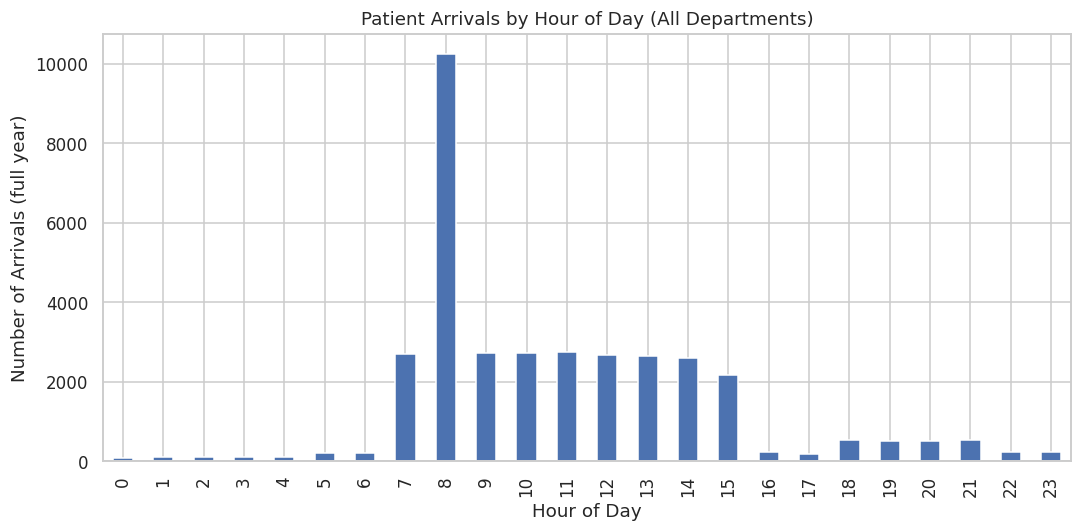

Peak arrival hour: 8:00 (10,240 arrivals)
Quietest hour (with any arrivals): 0:00 (81 arrivals)


In [76]:
hourly_arrivals = raw["Arrival_Hour"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
hourly_arrivals.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Number of Arrivals (full year)")
ax.set_title("Patient Arrivals by Hour of Day (All Departments)")
plt.tight_layout()
plt.savefig(CHART_DIR / "06_arrivals_by_hour.png", dpi=140, bbox_inches="tight")
plt.show()

print(f"Peak arrival hour: {hourly_arrivals.idxmax()}:00 ({hourly_arrivals.max():,} arrivals)")
print(f"Quietest hour (with any arrivals): {hourly_arrivals.idxmin()}:00 ({hourly_arrivals.min():,} arrivals)")


### 9.2 Peak vs. non-peak waiting time


In [77]:
peak_comparison = raw.groupby("Peak_Period")["Total_Waiting_Time_Valid"].agg(["mean", "median", "count"]).round(2)
peak_comparison


,mean,median,count
Peak_Period,,,
Non-Peak,6.26,0.00,21894
Peak,26.53,14.92,12834


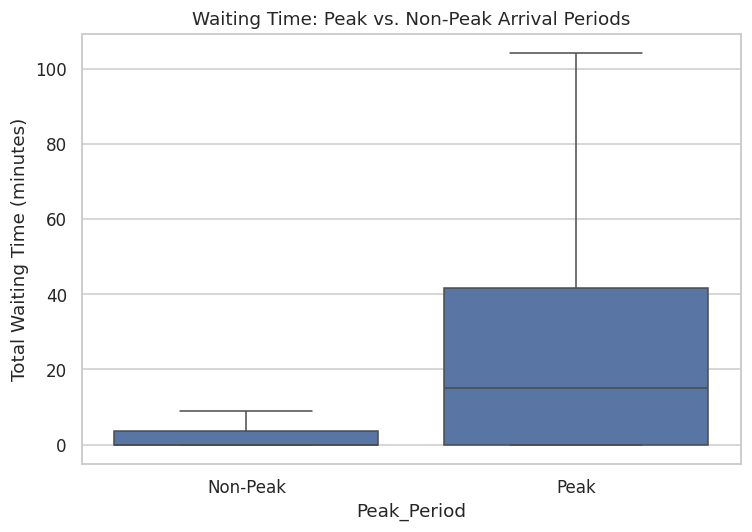

In [78]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=raw, x="Peak_Period", y="Total_Waiting_Time_Valid", ax=ax,
            showfliers=False, order=["Non-Peak", "Peak"])
ax.set_ylabel("Total Waiting Time (minutes)")
ax.set_title("Waiting Time: Peak vs. Non-Peak Arrival Periods")
plt.tight_layout()
plt.savefig(CHART_DIR / "07_peak_vs_nonpeak_waiting.png", dpi=140, bbox_inches="tight")
plt.show()


### 9.3 Daily and monthly patient-flow trend


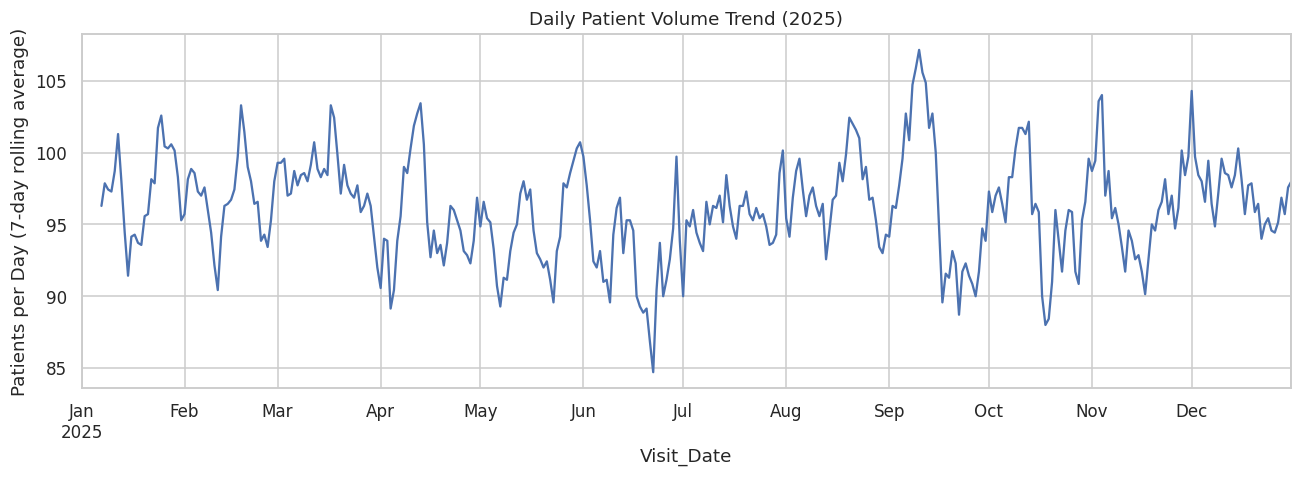

In [79]:
raw["Visit_Date"] = pd.to_datetime(raw["Visit_Date"])
daily_volume = raw.groupby("Visit_Date").size()

fig, ax = plt.subplots(figsize=(12, 4.5))
daily_volume.rolling(7).mean().plot(ax=ax, color="#4C72B0")
ax.set_ylabel("Patients per Day (7-day rolling average)")
ax.set_title("Daily Patient Volume Trend (2025)")
plt.tight_layout()
plt.savefig(CHART_DIR / "08_daily_volume_trend.png", dpi=140, bbox_inches="tight")
plt.show()


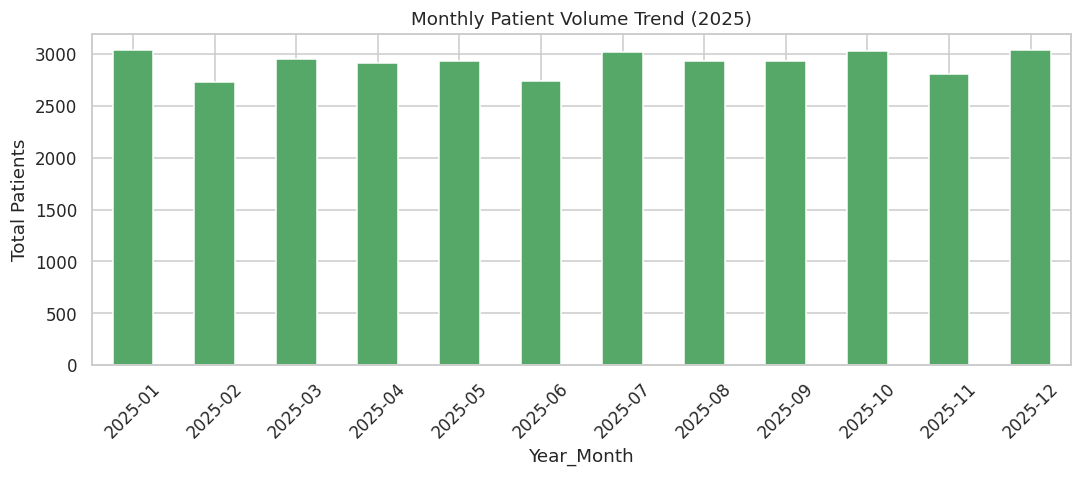

In [80]:
raw["Year_Month"] = raw["Visit_Date"].dt.to_period("M").astype(str)
monthly_volume = raw.groupby("Year_Month").size()

fig, ax = plt.subplots(figsize=(10, 4.5))
monthly_volume.plot(kind="bar", ax=ax, color="#55A868")
ax.set_ylabel("Total Patients")
ax.set_title("Monthly Patient Volume Trend (2025)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(CHART_DIR / "09_monthly_volume_trend.png", dpi=140, bbox_inches="tight")
plt.show()


## 10. Outlier Analysis

Section 4 flagged 1,650 encounters (4.70%) as LOS outliers using an IQR rule. That is a much larger share than the ~0.5% deliberately injected as extreme multipliers in Section 2 — worth investigating rather than assuming the IQR flag and the injected error are the same thing.


In [81]:
# Compare: does the IQR flag mostly catch the deliberately-injected extreme cases,
# or mostly catch genuine (if unusual) long encounters — e.g. admitted patients with lab+pharmacy?
outliers = raw[raw["LOS_Outlier_Flag"]]

print(f"LOS outliers by Disposition:")
print(outliers["Disposition"].value_counts(normalize=True).round(3))
print()
print(f"LOS outliers - share that also required Laboratory:  {outliers['Laboratory_Requested'].mean():.1%}")
print(f"LOS outliers - share that also required Pharmacy:    {outliers['Pharmacy_Needed'].mean():.1%}")
print(f"(For comparison, dataset-wide: Lab {raw['Laboratory_Requested'].mean():.1%}, Pharmacy {raw['Pharmacy_Needed'].mean():.1%})")


LOS outliers by Disposition:
Disposition
Discharged     0.81
Admitted       0.15
Referred Out   0.04
Name: proportion, dtype: float64

LOS outliers - share that also required Laboratory:  96.8%
LOS outliers - share that also required Pharmacy:    67.6%
(For comparison, dataset-wide: Lab 44.2%, Pharmacy 66.8%)


If admitted, lab-requiring, and pharmacy-requiring patients are heavily over-represented among the flagged outliers (compared to their dataset-wide shares above), that's evidence the IQR rule is mostly catching **genuinely long but explainable encounters** — admitted patients who also needed lab and pharmacy — rather than only the artificially injected extreme cases. That distinction matters operationally: a hospital manager reviewing "outliers" needs to know most of them aren't data errors to fix, they're real patients whose care legitimately took longer.


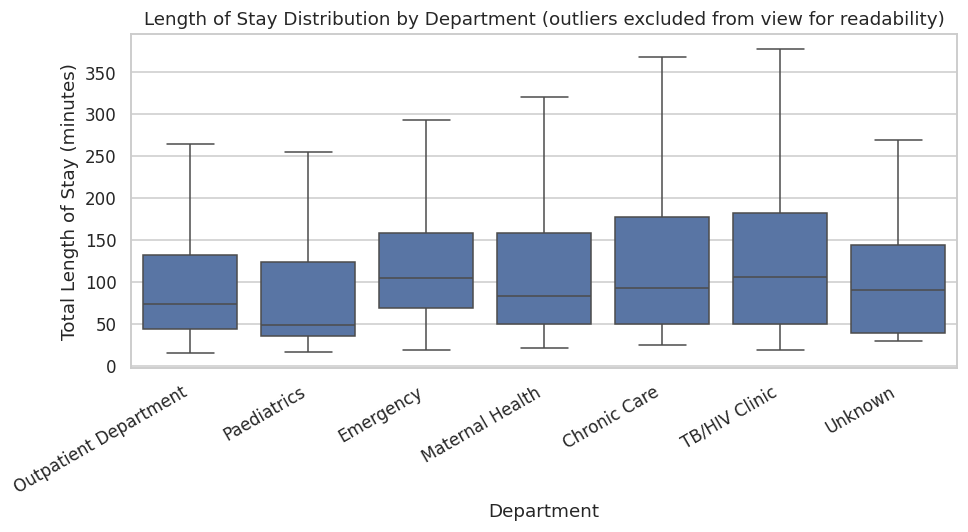

In [82]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=raw, x="Department", y="Total_Length_of_Stay", ax=ax, showfliers=False)
ax.set_ylabel("Total Length of Stay (minutes)")
ax.set_title("Length of Stay Distribution by Department (outliers excluded from view for readability)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(CHART_DIR / "10_los_boxplot_by_department.png", dpi=140, bbox_inches="tight")
plt.show()


## 11. Statistical Analysis

The tests below compare distributions and associations within the generated case-study data. With a large encounter count, very small p-values are easy to obtain; interpret them alongside group sizes, effect sizes, and operational context.

**Inference limitation:** Encounters share simulated staff queues and are therefore not fully independent. The conventional test p-values below are exploratory diagnostics, not confirmatory evidence. Real-world inference would require an appropriate design and methods that account for clustering and other sources of uncertainty.

### 11.1 Do waiting times differ significantly between departments?

Waiting time is heavily right-skewed (confirmed in Section 7.1), so a one-way ANOVA's normality assumption is questionable here. The non-parametric **Kruskal-Wallis test** (an ANOVA-like test that compares ranks instead of means, and doesn't assume normal distributions) is more appropriate and is used instead.


In [83]:
dept_groups = [
    raw.loc[(raw["Department"] == d) & raw["Total_Waiting_Time_Valid"].notna(), "Total_Waiting_Time_Valid"]
    for d in raw["Department"].unique() if d != "Unknown"
]
h_stat, p_value = stats.kruskal(*dept_groups)
print(f"Kruskal-Wallis H = {h_stat:.2f}, p = {p_value:.2e}")
if p_value < 0.05:
    print("-> Statistically significant difference in waiting time distributions between departments.")
else:
    print("-> No statistically significant difference detected.")


Kruskal-Wallis H = 5897.56, p = 0.00e+00
-> Statistically significant difference in waiting time distributions between departments.


**In practical terms:** this confirms what Section 8's department ranking already suggested visually — waiting times are not just randomly different by department due to chance, they differ in a way unlikely to arise if all departments actually had the same underlying waiting-time distribution. This justifies treating department as a real operational factor (not noise) when prioritizing where to improve patient flow.


### 11.2 Is queue size associated with waiting time?

Since both variables are continuous and waiting time is skewed, **Spearman's rank correlation** (robust to non-normal distributions and non-linear-but-monotonic relationships) is used alongside the Pearson correlation already computed in Section 1.5.


In [84]:
valid = raw.dropna(subset=["Queue_Size", "Total_Waiting_Time_Valid"])
rho, p_value = stats.spearmanr(valid["Queue_Size"], valid["Total_Waiting_Time_Valid"])
print(f"Spearman's rho = {rho:.3f}, p = {p_value:.2e}")
print(f"(Pearson correlation, for comparison: {valid['Queue_Size'].corr(valid['Total_Waiting_Time_Valid']):.3f})")


Spearman's rho = 0.883, p = 0.00e+00
(Pearson correlation, for comparison: 0.924)


**In practical terms:** both measures agree — queue size and waiting time move together strongly and consistently. Since queue size is observable in real time (unlike waiting time, which can only be measured after the fact), this supports a queue-monitoring or queue-alert system as a *leading indicator* a hospital could actually act on before a patient has already waited too long, rather than only reviewing waiting times retrospectively.


### 11.3 Do peak and non-peak periods have significantly different waiting times?

Two independent, non-normally-distributed groups -> the non-parametric **Mann-Whitney U test** (compares whether one group's values tend to be larger than the other's, without assuming normality) is used rather than a t-test.


**Interpretation guardrail:** the simulation uses FCFS consultation queues, not priority-based scheduling. This test compares groups in the generated dataset; it does not estimate the effect of triage priority or establish that peak arrivals cause longer waits. The 08:00–09:59 window is a shared reporting window; Emergency's simulated arrival peak is 18:00–21:59.

In [85]:
peak_waits = raw.loc[
    (raw["Peak_Period"] == "Peak") & raw["Total_Waiting_Time_Valid"].notna(),
    "Total_Waiting_Time_Valid"
]
nonpeak_waits = raw.loc[
    (raw["Peak_Period"] == "Non-Peak") & raw["Total_Waiting_Time_Valid"].notna(),
    "Total_Waiting_Time_Valid"
]

u_stat, p_value = stats.mannwhitneyu(
    peak_waits, nonpeak_waits, alternative="greater"
)
print(f"Peak median wait: {peak_waits.median():.1f} min | Non-peak median wait: {nonpeak_waits.median():.1f} min")
print(f"Peak P90 wait: {peak_waits.quantile(0.90):.1f} min | Non-peak P90 wait: {nonpeak_waits.quantile(0.90):.1f} min")
print(f"Mann-Whitney U = {u_stat:.0f}, p = {p_value:.2e} (one-sided: peak > non-peak)")
if p_value < 0.05:
    print("-> The observed peak-period wait distribution is higher in this case-study dataset.")
print("Interpret this as a within-model comparison, not a causal or facility-level conclusion.")

Peak median wait: 14.9 min | Non-peak median wait: 0.0 min
Peak P90 wait: 73.4 min | Non-peak P90 wait: 20.7 min
Mann-Whitney U = 209770573, p = 0.00e+00 (one-sided: peak > non-peak)
-> The observed peak-period wait distribution is higher in this case-study dataset.
Interpret this as a within-model comparison, not a causal or facility-level conclusion.


**Interpretation guardrail:** The test shows a higher observed wait distribution in the shared 08:00–09:59 reporting window in this simulated dataset. It does **not** establish that peak arrivals cause longer waits or directly justify staffing recommendations. Encounters share simulated queues, so the conventional p-value is exploratory; the window is also not each department's own peak (Emergency is modelled with an evening peak from 18:00–21:59). Staffing decisions would require department- and shift-specific demand/coverage analysis and validation with operational data.


### 11.4 Are laboratory requirements associated with longer total visits?

Same non-parametric logic as 11.3 — two independent groups (lab-required vs. not), non-normal `Total_Length_of_Stay`.


In [86]:
lab_los = raw.loc[raw["Laboratory_Requested"], "Total_Length_of_Stay"]
no_lab_los = raw.loc[~raw["Laboratory_Requested"], "Total_Length_of_Stay"]

u_stat, p_value = stats.mannwhitneyu(lab_los, no_lab_los, alternative="greater")
print(f"Median LOS WITH lab request:    {lab_los.median():.1f} min")
print(f"Median LOS WITHOUT lab request: {no_lab_los.median():.1f} min")
print(f"Mann-Whitney U = {u_stat:.0f}, p = {p_value:.2e} (one-sided: with-lab > without-lab)")




Median LOS WITH lab request:    152.8 min
Median LOS WITHOUT lab request: 46.7 min
Mann-Whitney U = 281786035, p = 0.00e+00 (one-sided: with-lab > without-lab)


**Interpretation guardrail:** Laboratory processing time is explicitly added to the visit timeline for patients who request a test. A longer stay in this group is therefore an expected consequence of the model structure, not independent evidence that laboratory testing causes longer stays.

**In practical terms:** this is expected by construction (the simulation adds lab processing time to any visit requiring it), but confirming it statistically — rather than assuming it — is still the correct practice, and it quantifies *how much* longer, which is the number that matters for planning (see Section 12's final summary).


## 12. Final Summary


In [87]:
valid_wait_mask = raw["Total_Waiting_Time_Valid"].notna()

print(f"Total patient encounters analysed: {len(raw):,}")
print(f"Valid waiting-time cohort: {valid_wait_mask.sum():,}")
print(f"Departments: {raw[raw['Department']!='Unknown']['Department'].nunique()}")
print(f"Overall median waiting time: {raw.loc[valid_wait_mask, 'Total_Waiting_Time_Valid'].median():.1f} min")
print(f"Overall mean waiting time: {raw.loc[valid_wait_mask, 'Total_Waiting_Time_Valid'].mean():.1f} min")
print(f"Share waiting >60 minutes (valid cohort): {raw.loc[valid_wait_mask, 'Long_Wait_Flag'].mean():.1%}")
print(f"Overall mean Total_Length_of_Stay: {raw['Total_Length_of_Stay'].mean():.1f} min")
print(f"Peak arrival hour (all departments): {hourly_arrivals.idxmax()}:00")
print(f"Highest-congestion department (avg wait): {dept_performance['Avg_Wait_Min'].idxmax()}")
print(f"Department with highest long-wait rate: {dept_performance['Long_Wait_Pct'].idxmax()} ({dept_performance['Long_Wait_Pct'].max():.1%})")

Total patient encounters analysed: 35,082
Valid waiting-time cohort: 34,728
Departments: 6
Overall median waiting time: 0.0 min
Overall mean waiting time: 13.8 min
Share waiting >60 minutes (valid cohort): 7.1%
Overall mean Total_Length_of_Stay: 111.5 min
Peak arrival hour (all departments): 8:00
Highest-congestion department (avg wait): Outpatient Department
Department with highest long-wait rate: Outpatient Department (15.1%)


## 13. Export Cleaned Dataset


In [88]:
output_dir = PROCESSED_DATA_DIR
output_file = output_dir / "hospital_patient_flow_clean.csv"
raw.to_csv(output_file, index=False)
print(f"Saved: {raw.shape[0]:,} rows x {raw.shape[1]} columns -> {output_file}")


Saved: 35,082 rows x 50 columns -> /content/data/processed/hospital_patient_flow_clean.csv


### Recap

1. **Simulated** a full year of patient flow across six departments, with department-level registration, triage and consultation capacity plus shared Laboratory and Pharmacy queues. Queues are processed within each day; server availability resets at midnight, so overnight carry-over is outside this model.
2. **Introduced** data-quality cases including missing values, duplicate records, impossible timestamps, negative waits, extreme length-of-stay values and inconsistent department labels.
3. **Inspected and cleaned** the records with focused checks for the injected anomalies. The repository cleaning module applies additional stage-level timing and waiting checks for the dashboard pipeline.
4. **Engineered** arrival-hour, shared-window peak, valid long-wait and hospital-wide congestion indicators using definitions aligned with the repository analysis pipeline.
5. Ran **descriptive, department, stage, peak-period and outlier analyses**, interpreting the distribution and upper tail rather than relying on averages alone.
6. Ran **four exploratory statistical tests** (Kruskal–Wallis, two Mann–Whitney U tests and Spearman correlation). Because encounters share simulated queues, observations are dependent; p-values are diagnostic and should not be treated as confirmatory evidence.
7. **Exported** the cleaned dataset for further repository SQL and dashboard workflows; the dashboard's canonical processed dataset is generated by the repository pipeline.

The notebook's findings are calculated from the generated case-study records. They describe the model and its assumptions, not the performance of an operating health facility.
